DATASET SUMMARY
----------------
Number of measurements: 139
Wavelength range: 79.80–100.00 nm
Minimum cross section: 1.860e-19 cm²/molecule
Maximum cross section: 3.020e-16 cm²/molecule

SLAB CALCULATION
----------------
Temperature: 295.0 K
Pressure: 100.0 Pa
Length: 10.0 cm
Number density: 2.455e+16 molecules/cm³
Maximum optical depth: 74.15
Minimum transmission: 6.277e-33
Maximum transmission: 0.9554


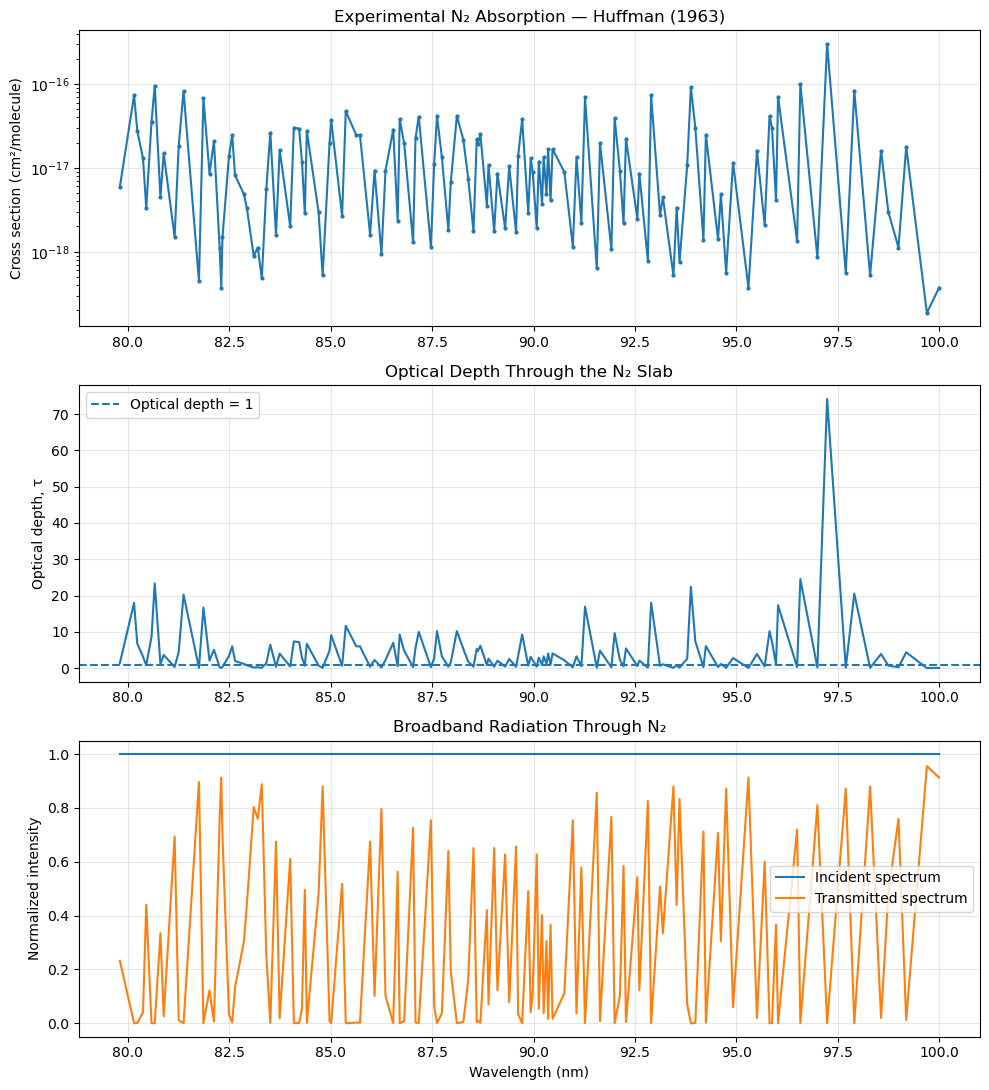

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# 1. LOAD THE EXPERIMENTAL HUFFMAN DATA
# =====================================================

file_path = "Huffman(1963)_295K_79-100nm.txt"

data = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None,
    names=["wavelength_nm", "sigma_cm2"]
)

wavelength = data["wavelength_nm"].to_numpy()
sigma = data["sigma_cm2"].to_numpy()

# Basic validation
assert len(data) > 1, "Not enough data points."
assert np.all(np.isfinite(data.to_numpy())), "Non-finite data found."
assert np.all(np.diff(wavelength) > 0), "Wavelengths must increase."
assert np.all(sigma > 0), "Cross sections must be positive."

print("DATASET SUMMARY")
print("----------------")
print("Number of measurements:", len(data))
print(f"Wavelength range: {wavelength.min():.2f}–{wavelength.max():.2f} nm")
print(f"Minimum cross section: {sigma.min():.3e} cm²/molecule")
print(f"Maximum cross section: {sigma.max():.3e} cm²/molecule")

# =====================================================
# 2. SET THE GAS SLAB PARAMETERS
# =====================================================

k_B = 1.380649e-23  # Boltzmann constant, J/K

T = 295.0           # Gas temperature, K
P = 100.0           # N₂ pressure, Pa
L = 10.0            # Slab length, cm

# Ideal gas number density:
# First calculate molecules/m³, then convert to molecules/cm³.
number_density = P / (k_B * T) / 1e6

# Optical depth and transmission
tau = number_density * sigma * L
transmission = np.exp(-tau)

# Assume a flat incident spectrum, I_in = 1.
I_in = np.ones_like(wavelength)
I_out = I_in * transmission

print("\nSLAB CALCULATION")
print("----------------")
print(f"Temperature: {T:.1f} K")
print(f"Pressure: {P:.1f} Pa")
print(f"Length: {L:.1f} cm")
print(f"Number density: {number_density:.3e} molecules/cm³")
print(f"Maximum optical depth: {tau.max():.4g}")
print(f"Minimum transmission: {transmission.min():.4g}")
print(f"Maximum transmission: {transmission.max():.4g}")

# =====================================================
# 3. PLOT THE EXPERIMENTAL CROSS SECTION
# =====================================================

fig, axes = plt.subplots(3, 1, figsize=(10, 11))

axes[0].plot(wavelength, sigma, marker=".", markersize=4)
axes[0].set_yscale("log")
axes[0].set_ylabel("Cross section (cm²/molecule)")
axes[0].set_title("Experimental N₂ Absorption — Huffman (1963)")
axes[0].grid(True, alpha=0.3)

# =====================================================
# 4. PLOT OPTICAL DEPTH
# =====================================================

axes[1].plot(wavelength, tau)
axes[1].axhline(1, linestyle="--", label="Optical depth = 1")
axes[1].set_ylabel("Optical depth, τ")
axes[1].set_title("Optical Depth Through the N₂ Slab")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# =====================================================
# 5. PLOT INCIDENT AND TRANSMITTED SPECTRA
# =====================================================

axes[2].plot(wavelength, I_in, label="Incident spectrum")
axes[2].plot(wavelength, I_out, label="Transmitted spectrum")
axes[2].set_xlabel("Wavelength (nm)")
axes[2].set_ylabel("Normalized intensity")
axes[2].set_title("Broadband Radiation Through N₂")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [2]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# =====================================================
# 1. LOAD EXPERIMENTAL DATA
# =====================================================

file_path = "Huffman(1963)_295K_79-100nm.txt"

data = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None,
    names=["wavelength_nm", "sigma_cm2"]
)

wavelength = data["wavelength_nm"].to_numpy()
sigma = data["sigma_cm2"].to_numpy()

# Boltzmann constant
k_B = 1.380649e-23  # J/K

# =====================================================
# 2. CALCULATION FUNCTION
# =====================================================

def calculate_slab(T, P, L):
    """
    T: temperature in K
    P: pressure in Pa
    L: slab length in cm

    Cross section is in cm^2/molecule.
    Number density is converted to molecules/cm^3.
    """

    n = P / (k_B * T) / 1e6

    tau = n * sigma * L
    transmission = np.exp(-tau)

    # Flat, normalized incident spectrum
    I_in = np.ones_like(wavelength)
    I_out = I_in * transmission

    return n, tau, transmission, I_in, I_out

# =====================================================
# 3. PLOT UPDATE FUNCTION
# =====================================================

output = widgets.Output()

def update_plots(T, P, L):

    n, tau, transmission, I_in, I_out = calculate_slab(T, P, L)

    with output:
        clear_output(wait=True)

        fig, axes = plt.subplots(2, 2, figsize=(12, 8))

        # Experimental cross section
        axes[0, 0].plot(wavelength, sigma, marker=".", markersize=3)
        axes[0, 0].set_yscale("log")
        axes[0, 0].set_title("Experimental N₂ cross section")
        axes[0, 0].set_xlabel("Wavelength (nm)")
        axes[0, 0].set_ylabel("σ (cm²/molecule)")
        axes[0, 0].grid(True, alpha=0.3)

        # Optical depth
        axes[0, 1].plot(wavelength, tau)
        axes[0, 1].axhline(1, linestyle="--", label="τ = 1")
        axes[0, 1].set_title("Optical depth")
        axes[0, 1].set_xlabel("Wavelength (nm)")
        axes[0, 1].set_ylabel("τ")
        axes[0, 1].legend()
        axes[0, 1].grid(True, alpha=0.3)

        # Transmission
        axes[1, 0].plot(wavelength, transmission)
        axes[1, 0].set_ylim(-0.03, 1.03)
        axes[1, 0].set_title("Fraction of light transmitted")
        axes[1, 0].set_xlabel("Wavelength (nm)")
        axes[1, 0].set_ylabel("Iout / Iin")
        axes[1, 0].grid(True, alpha=0.3)

        # Incident and transmitted spectrum
        axes[1, 1].plot(wavelength, I_in, label="Incident")
        axes[1, 1].plot(wavelength, I_out, label="Transmitted")
        axes[1, 1].set_ylim(-0.03, 1.1)
        axes[1, 1].set_title("Broadband radiation")
        axes[1, 1].set_xlabel("Wavelength (nm)")
        axes[1, 1].set_ylabel("Normalized intensity")
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

        print(f"Number density: {n:.3e} molecules/cm³")
        print(f"Maximum optical depth: {tau.max():.4g}")
        print(f"Minimum transmission: {transmission.min():.4g}")
        print(f"Maximum transmission: {transmission.max():.4g}")

# =====================================================
# 4. INTERACTIVE CONTROLS
# =====================================================

temperature = widgets.FloatSlider(
    value=295, min=100, max=1000, step=5,
    description="T (K)", continuous_update=False
)

pressure = widgets.FloatLogSlider(
    value=100, base=10, min=-1, max=5, step=0.1,
    description="P (Pa)", continuous_update=False
)

length = widgets.FloatLogSlider(
    value=10, base=10, min=-1, max=3, step=0.1,
    description="L (cm)", continuous_update=False
)

controls = widgets.VBox([temperature, pressure, length])

ui = widgets.interactive_output(
    update_plots,
    {"T": temperature, "P": pressure, "L": length}
)

display(controls, ui)


Output()

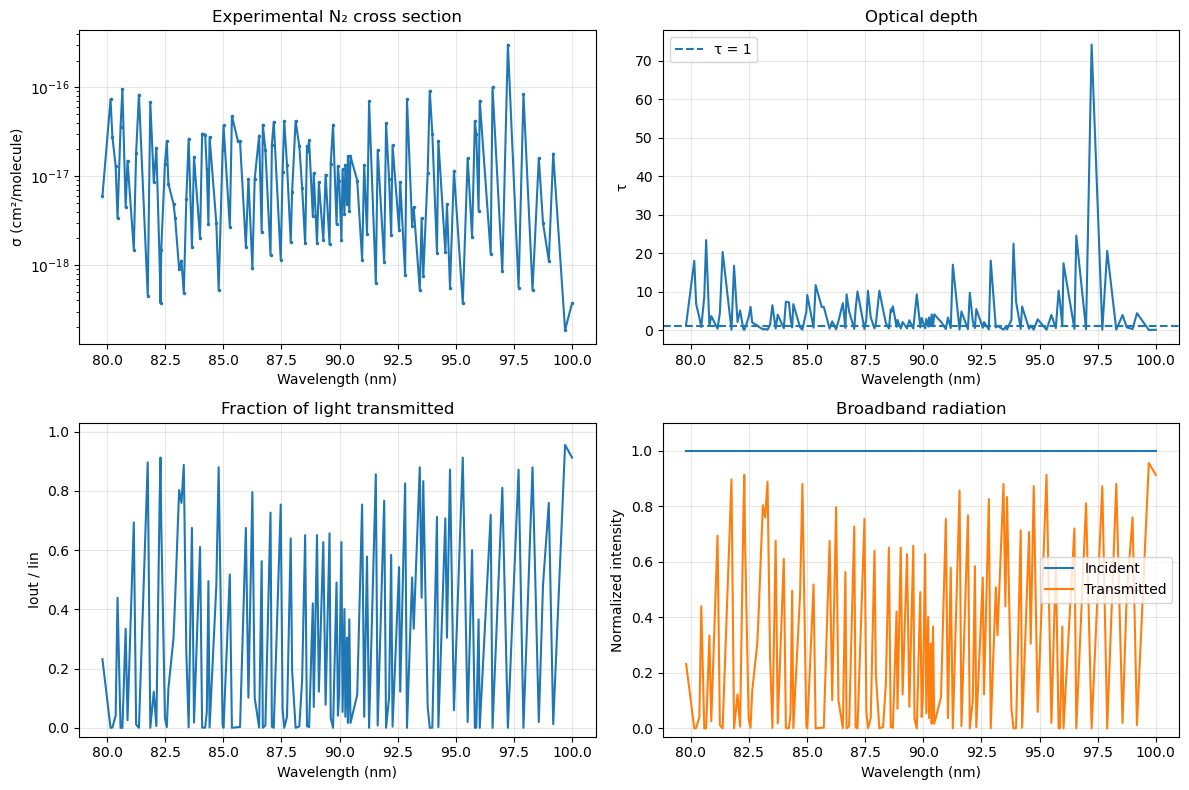

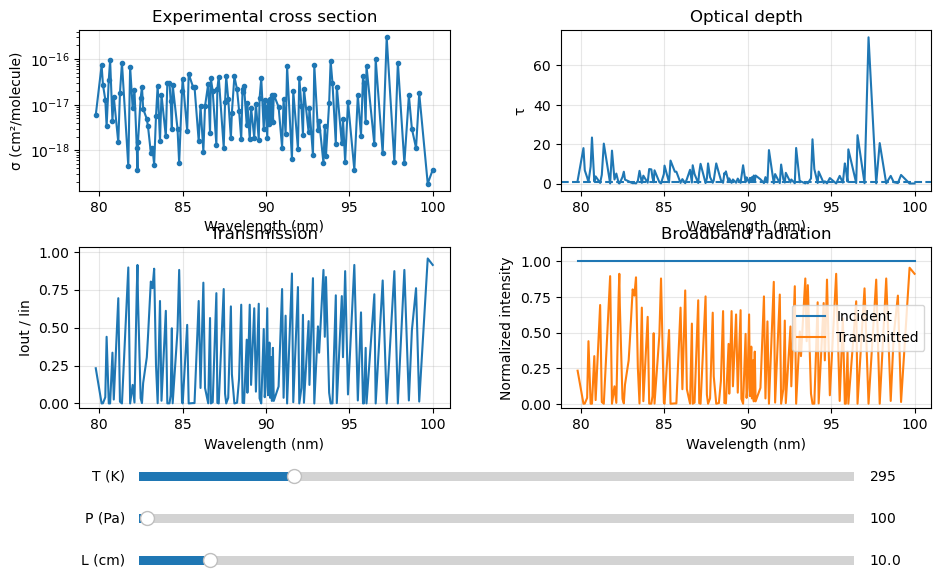

In [7]:

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from IPython.display import display

k_B = 1.380649e-23

# Initial parameters
T0 = 295.0
P0 = 100.0
L0 = 10.0

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plt.subplots_adjust(bottom=0.34, hspace=0.35, wspace=0.30)

ax_sigma, ax_tau, ax_trans, ax_spectrum = axes.flat

# Experimental cross section
ax_sigma.plot(wavelength, sigma, ".-")
ax_sigma.set_yscale("log")
ax_sigma.set_title("Experimental cross section")
ax_sigma.set_xlabel("Wavelength (nm)")
ax_sigma.set_ylabel("σ (cm²/molecule)")
ax_sigma.grid(True, alpha=0.3)

# Optical depth
n0 = P0 / (k_B * T0) / 1e6
tau0 = n0 * sigma * L0
line_tau, = ax_tau.plot(wavelength, tau0)
ax_tau.axhline(1, linestyle="--")
ax_tau.set_title("Optical depth")
ax_tau.set_xlabel("Wavelength (nm)")
ax_tau.set_ylabel("τ")
ax_tau.grid(True, alpha=0.3)

# Transmission
trans0 = np.exp(-tau0)
line_trans, = ax_trans.plot(wavelength, trans0)
ax_trans.set_ylim(-0.03, 1.03)
ax_trans.set_title("Transmission")
ax_trans.set_xlabel("Wavelength (nm)")
ax_trans.set_ylabel("Iout / Iin")
ax_trans.grid(True, alpha=0.3)

# Incident and transmitted spectra
line_in, = ax_spectrum.plot(wavelength, np.ones_like(wavelength),
                            label="Incident")
line_out, = ax_spectrum.plot(wavelength, trans0, label="Transmitted")
ax_spectrum.set_ylim(-0.03, 1.1)
ax_spectrum.set_title("Broadband radiation")
ax_spectrum.set_xlabel("Wavelength (nm)")
ax_spectrum.set_ylabel("Normalized intensity")
ax_spectrum.legend()
ax_spectrum.grid(True, alpha=0.3)

# Slider locations
ax_T = fig.add_axes([0.18, 0.23, 0.65, 0.025])
ax_P = fig.add_axes([0.18, 0.17, 0.65, 0.025])
ax_L = fig.add_axes([0.18, 0.11, 0.65, 0.025])

slider_T = Slider(ax_T, "T (K)", 100, 1000, valinit=T0)
slider_P = Slider(ax_P, "P (Pa)", 0, 10000, valinit=P0)
slider_L = Slider(ax_L, "L (cm)", 0.1, 100, valinit=L0)

def update(val):
    T = slider_T.val
    P = slider_P.val
    L = slider_L.val

    n = P / (k_B * T) / 1e6
    tau = n * sigma * L
    trans = np.exp(-tau)

    line_tau.set_ydata(tau)
    line_trans.set_ydata(trans)
    line_out.set_ydata(trans)

    ax_tau.set_ylim(0, max(1.0, float(tau.max()) * 1.1))

    fig.canvas.draw_idle()

slider_T.on_changed(update)
slider_P.on_changed(update)
slider_L.on_changed(update)

plt.show()


In [16]:
%pip install ipympl

   ---------------------------------------- 0.0/519.0 kB ? eta -:--:--
   -- ------------------------------------ 30.7/519.0 kB 660.6 kB/s eta 0:00:01
   ---- ----------------------------------- 61.4/519.0 kB 1.1 MB/s eta 0:00:01
   -------- ----------------------------- 112.6/519.0 kB 819.2 kB/s eta 0:00:01
   -------- ----------------------------- 122.9/519.0 kB 722.1 kB/s eta 0:00:01
   ---------- --------------------------- 143.4/519.0 kB 774.0 kB/s eta 0:00:01
   ------------ ------------------------- 174.1/519.0 kB 655.4 kB/s eta 0:00:01
   -------------- ----------------------- 194.6/519.0 kB 655.9 kB/s eta 0:00:01
   -------------- ----------------------- 204.8/519.0 kB 565.6 kB/s eta 0:00:01
   -------------- ----------------------- 204.8/519.0 kB 565.6 kB/s eta 0:00:01
   -------------- ----------------------- 204.8/519.0 kB 565.6 kB/s eta 0:00:01
   -------------- ----------------------- 204.8/519.0 kB 565.6 kB/s eta 0:00:01
   ---------------- --------------------- 225.3/51

In [1]:
%matplotlib

Using matplotlib backend: <object object at 0x000002E5A2F775B0>


In [3]:
%matplotlib widget

In [9]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)

import ipywidgets
print("ipywidgets version:", ipywidgets.__version__)

try:
    import ipympl
    print("ipympl version:", ipympl.__version__)
except ImportError as e:
    print("ipympl import error:", e)

try:
    import matplotlib
    print("matplotlib version:", matplotlib.__version__)
    print("Backend:", matplotlib.get_backend())
except Exception as e:
    print("matplotlib error:", e)

Python executable: C:\Users\sreeg\anaconda3\python.exe
Python version: 3.11.7 | packaged by Anaconda, Inc. | (main, Dec 15 2023, 18:05:47) [MSC v.1916 64 bit (AMD64)]
ipywidgets version: 7.6.5
ipympl version: 0.10.0
matplotlib version: 3.8.0
Backend: module://matplotlib_inline.backend_inline


In [3]:
import ipywidgets as widgets
from IPython.display import display

display(widgets.IntSlider(
    value=5,
    min=0,
    max=10,
    description="Test:"
))

IntSlider(value=5, description='Test:', max=10)

In [7]:
%pip install -U "ipywidgets>=8"

   ---------------------------------------- 0.0/140.1 kB ? eta -:--:--
   -------------------------------- ------- 112.6/140.1 kB 3.2 MB/s eta 0:00:01
   ---------------------------------------- 140.1/140.1 kB 1.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/217.3 kB ? eta -:--:--
   ------------------------------ --------- 163.8/217.3 kB 5.0 MB/s eta 0:00:01
   ---------------------------------------- 217.3/217.3 kB 4.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.2 MB 6.8 MB/s eta 0:00:01
   -------------- ------------------------- 0.8/2.2 MB 8.4 MB/s eta 0:00:01
   ---------------------- ----------------- 1.2/2.2 MB 8.6 MB/s eta 0:00:01
   -------------------------------- ------- 1.8/2.2 MB 9.4 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 9.4 MB/s eta 0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbexte

In [1]:
import ipywidgets
print(ipywidgets.__version__)   # should be 8.x

8.1.9


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Adjust the path to wherever the file lives on your machine
wl, sigma = np.loadtxt("Huffman_1963__295K_79-100nm.txt", unpack=True)

wl_slider = widgets.FloatRangeSlider(
    value=[wl.min(), wl.max()], min=wl.min(), max=wl.max(), step=0.05,
    description="λ range (nm):", style={"description_width": "initial"},
    layout=widgets.Layout(width="500px"), continuous_update=False,
)
bin_slider = widgets.FloatSlider(
    value=0.0, min=0.0, max=5.0, step=0.1,
    description="Bin width (nm):", style={"description_width": "initial"},
    layout=widgets.Layout(width="500px"), continuous_update=False,
)
log_box = widgets.Checkbox(value=True, description="Log y-axis")

def plot(wl_range, bin_width, logy):
    lo, hi = wl_range
    m = (wl >= lo) & (wl <= hi)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(wl[m], sigma[m], ".", ms=4, label="Huffman (1963), 295 K")

    if bin_width > 0:
        edges = np.arange(lo, hi + bin_width, bin_width)
        idx = np.digitize(wl[m], edges)
        centers, means = [], []
        for i in np.unique(idx):
            sel = idx == i
            centers.append(wl[m][sel].mean())
            means.append(sigma[m][sel].mean())
        ax.step(centers, means, where="mid", color="C1", label=f"{bin_width:g} nm bin avg")

    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Cross section (cm$^2$, assumed)")
    ax.legend()
    ax.set_title(f"{m.sum()} points in window")
    plt.show()

out = widgets.interactive_output(
    plot, {"wl_range": wl_slider, "bin_width": bin_slider, "logy": log_box}
)
display(widgets.VBox([wl_slider, bin_slider, log_box]), out)